Using device: cpu

--- Task 2.1 & 2.2: NumPy Math ---
NumPy LSTM h_t output: [ 0.06163682 -0.28163594  0.29831283  0.07323971]
Theoretical Parameters (I=64, H=128): {'RNN': 24704, 'GRU': 74112, 'LSTM': 98816}

--- Task 4.1: Training Models ---
[GRU] Training Time: 21.79s
[GRU] Avg Inference Latency per batch: 7.76ms
[LSTM] Training Time: 27.02s
[LSTM] Avg Inference Latency per batch: 10.46ms
Loss plots saved as 'loss_plot.png'.

--- Exposure Bias Analysis (GRU) ---
Autoregressive Loss (TF=0.0): 1.4395
Guided Loss (TF=1.0): 1.4432
Exposure Bias Penalty Gap: -0.0037

--- Task 5.1: BLEU Evaluation ---
Model Architecture   | Short      | Medium     | Long       | Overall
----------------------------------------------------------------------
GRU-Seq2Seq          | 0.0600     | 0.0732     | 0.0883     | 0.0741
LSTM-Seq2Seq         | 0.1318     | 0.1832     | 0.1720     | 0.1689

--- Task 5.2: Qualitative Translation Evaluation ---

Source: the old girl chases the red ball
Ground Truth: redai

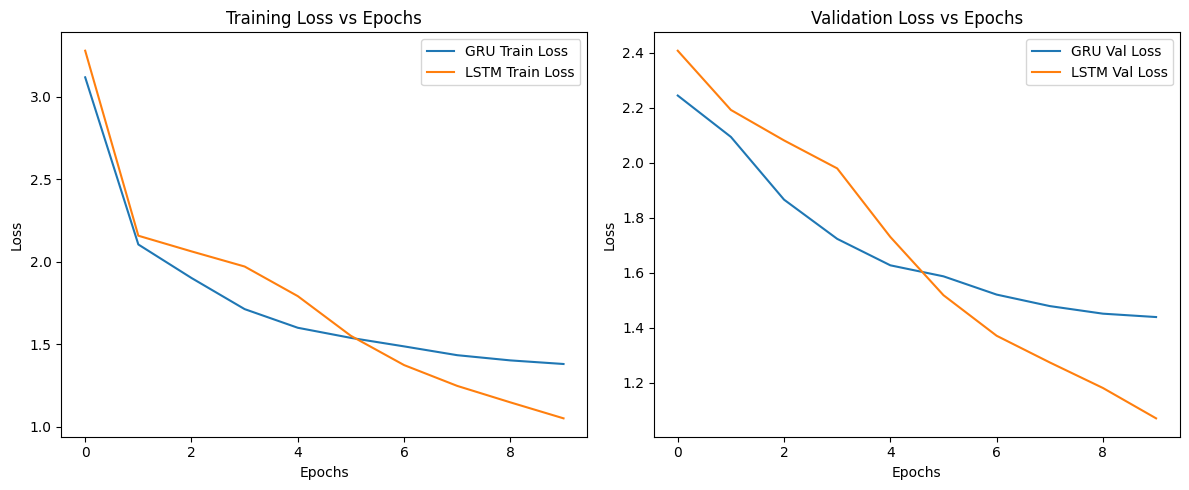

In [8]:
import json
import torch
import torch.nn as nn
import numpy as np
import random
import time
import matplotlib.pyplot as plt
from collections import defaultdict
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# ==========================================
# Global Hyperparameters & Reproducibility
# ==========================================
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

MAX_LEN = 50
BATCH_SIZE = 64
EMBEDDING_DIM = 64
HIDDEN_DIM = 128
LEARNING_RATE = 0.001
EPOCHS = 10
TEACHER_FORCING_RATIO = 0.5
CLIP_MAX_NORM = 1.0

PAD_IDX = 0
SOS_IDX = 1
EOS_IDX = 2
UNK_IDX = 3

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==========================================
# 1. Dataset Loading and Preparation
# ==========================================
def load_jsonl(path):
    data = []
    with open(path, 'r') as f:
        for line in f:
            data.append(json.loads(line.strip()))
    return data

def process_sequences(data, src_vocab, tgt_vocab, is_train=False):
    processed = []
    for item in data:
        src_tokens = item['src'].strip().split()
        tgt_tokens = item['tgt'].strip().split()
        
        if is_train:
            for w in src_tokens: 
                if w not in src_vocab: src_vocab[w] = len(src_vocab)
            for w in tgt_tokens: 
                if w not in tgt_vocab: tgt_vocab[w] = len(tgt_vocab)
        
        # Truncate and wrap
        src_idx = [SOS_IDX] + [src_vocab.get(w, UNK_IDX) for w in src_tokens[:MAX_LEN-2]] + [EOS_IDX]
        tgt_idx = [SOS_IDX] + [tgt_vocab.get(w, UNK_IDX) for w in tgt_tokens[:MAX_LEN-2]] + [EOS_IDX]
        
        # Pad
        src_idx += [PAD_IDX] * (MAX_LEN - len(src_idx))
        tgt_idx += [PAD_IDX] * (MAX_LEN - len(tgt_idx))
        
        processed.append({
            'src': src_idx, 
            'tgt': tgt_idx, 
            'bucket': item.get('length_bucket', 'unknown')
        })
    return processed

def get_batches(data, batch_size):
    for i in range(0, len(data), batch_size):
        batch = data[i:i+batch_size]
        src_tensors = torch.tensor([item['src'] for item in batch], dtype=torch.long).to(DEVICE)
        tgt_tensors = torch.tensor([item['tgt'] for item in batch], dtype=torch.long).to(DEVICE)
        buckets = [item['bucket'] for item in batch]
        yield src_tensors, tgt_tensors, buckets

# ==========================================
# 2. The Math of Gated Cells (NumPy)
# ==========================================
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def lstm_cell_forward(x_t, h_prev, c_prev, W, b):
    hidden_dim = len(h_prev)
    stacked = np.concatenate([h_prev, x_t])
    gates = np.dot(W, stacked) + b
    
    f_t = sigmoid(gates[:hidden_dim])
    i_t = sigmoid(gates[hidden_dim:2*hidden_dim])
    c_tilde = np.tanh(gates[2*hidden_dim:3*hidden_dim])
    o_t = sigmoid(gates[3*hidden_dim:])
    
    c_t = f_t * c_prev + i_t * c_tilde
    h_t = o_t * np.tanh(c_t)
    
    return h_t, c_t

def calculate_parameters(input_dim, hidden_dim):
    base_gate_params = (hidden_dim * (hidden_dim + input_dim)) + hidden_dim
    return {
        "RNN": base_gate_params, 
        "GRU": 3 * base_gate_params, 
        "LSTM": 4 * base_gate_params
    }

# ==========================================
# 3. Gated Seq2Seq Architectures (PyTorch)
# ==========================================
class EncoderGRU(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMBEDDING_DIM, padding_idx=PAD_IDX)
        self.rnn = nn.GRU(EMBEDDING_DIM, HIDDEN_DIM, batch_first=True)
    def forward(self, src):
        _, hidden = self.rnn(self.embedding(src))
        return hidden

class DecoderGRU(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.vocab_size = vocab_size
        self.embedding = nn.Embedding(vocab_size, EMBEDDING_DIM, padding_idx=PAD_IDX)
        self.rnn = nn.GRU(EMBEDDING_DIM, HIDDEN_DIM, batch_first=True)
        self.fc = nn.Linear(HIDDEN_DIM, vocab_size)
    def forward(self, input, hidden):
        output, hidden = self.rnn(self.embedding(input.unsqueeze(1)), hidden)
        return self.fc(output.squeeze(1)), hidden

class EncoderLSTM(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMBEDDING_DIM, padding_idx=PAD_IDX)
        self.rnn = nn.LSTM(EMBEDDING_DIM, HIDDEN_DIM, batch_first=True)
    def forward(self, src):
        _, (hidden, cell) = self.rnn(self.embedding(src))
        return hidden, cell

class DecoderLSTM(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.vocab_size = vocab_size
        self.embedding = nn.Embedding(vocab_size, EMBEDDING_DIM, padding_idx=PAD_IDX)
        self.rnn = nn.LSTM(EMBEDDING_DIM, HIDDEN_DIM, batch_first=True)
        self.fc = nn.Linear(HIDDEN_DIM, vocab_size)
    def forward(self, input, hidden_tuple):
        output, hidden_tuple = self.rnn(self.embedding(input.unsqueeze(1)), hidden_tuple)
        return self.fc(output.squeeze(1)), hidden_tuple

class GatedSeq2Seq(nn.Module):
    def __init__(self, encoder, decoder, cell_type='gru'):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.cell_type = cell_type
        
    def forward(self, src, tgt, tf_ratio=TEACHER_FORCING_RATIO):
        batch_size = src.shape[0]
        tgt_len = tgt.shape[1]
        vocab_size = self.decoder.vocab_size
        
        outputs = torch.zeros(batch_size, tgt_len, vocab_size).to(DEVICE)
        context = self.encoder(src)
        
        input_token = tgt[:, 0]
        for t in range(1, tgt_len):
            output, context = self.decoder(input_token, context)
            outputs[:, t] = output
            top1 = output.argmax(1)
            input_token = tgt[:, t] if random.random() < tf_ratio else top1
            
        return outputs

# ==========================================
# 4. Comparative Training & Exposure Bias
# ==========================================
def train_model(model, train_data, val_data, epochs=EPOCHS):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
    train_hist, val_hist = [], []
    
    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        for src, tgt, _ in get_batches(train_data, BATCH_SIZE):
            optimizer.zero_grad()
            output = model(src, tgt)
            output = output[:, 1:].reshape(-1, output.shape[-1])
            tgt_flat = tgt[:, 1:].reshape(-1)
            
            loss = criterion(output, tgt_flat)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_MAX_NORM)
            optimizer.step()
            epoch_loss += loss.item()
            
        train_hist.append(epoch_loss / (len(train_data)/BATCH_SIZE))
        
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for src, tgt, _ in get_batches(val_data, BATCH_SIZE):
                output = model(src, tgt, tf_ratio=0.0)
                output = output[:, 1:].reshape(-1, output.shape[-1])
                tgt_flat = tgt[:, 1:].reshape(-1)
                val_loss += criterion(output, tgt_flat).item()
        val_hist.append(val_loss / (len(val_data)/BATCH_SIZE))
        
    total_time = time.time() - start_time
    print(f"[{model.cell_type.upper()}] Training Time: {total_time:.2f}s")
    
    # Calculate inference latency
    model.eval()
    dummy_src, dummy_tgt, _ = next(get_batches(val_data, BATCH_SIZE))
    inf_start = time.time()
    with torch.no_grad():
        _ = model(dummy_src, dummy_tgt, tf_ratio=0.0)
    inf_latency = (time.time() - inf_start) * 1000
    print(f"[{model.cell_type.upper()}] Avg Inference Latency per batch: {inf_latency:.2f}ms")
    
    return train_hist, val_hist

def exposure_bias_analysis(model, val_data):
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
    model.eval()
    losses = {}
    with torch.no_grad():
        for tf_ratio, key in zip([0.0, 1.0], ['tf_0', 'tf_1']):
            total_loss = 0
            for src, tgt, _ in get_batches(val_data, BATCH_SIZE):
                output = model(src, tgt, tf_ratio=tf_ratio)
                output = output[:, 1:].reshape(-1, output.shape[-1])
                tgt_flat = tgt[:, 1:].reshape(-1)
                total_loss += criterion(output, tgt_flat).item()
            losses[key] = total_loss / (len(val_data)/BATCH_SIZE)
            
    print(f"\n--- Exposure Bias Analysis ({model.cell_type.upper()}) ---")
    print(f"Autoregressive Loss (TF=0.0): {losses['tf_0']:.4f}")
    print(f"Guided Loss (TF=1.0): {losses['tf_1']:.4f}")
    print(f"Exposure Bias Penalty Gap: {losses['tf_0'] - losses['tf_1']:.4f}\n")

# ==========================================
# 5. Evaluating Long-Term Dependencies
# ==========================================
def evaluate_bleu(model, test_data, tgt_vocab):
    idx_to_tgt = {v: k for k, v in tgt_vocab.items()}
    model.eval()
    
    refs = defaultdict(list)
    hypos = defaultdict(list)
    
    with torch.no_grad():
        for src, tgt, buckets in get_batches(test_data, BATCH_SIZE):
            output = model(src, tgt, tf_ratio=0.0)
            preds = output.argmax(2)
            
            for pred, target, bucket in zip(preds, tgt, buckets):
                pred_tokens = [idx_to_tgt[idx.item()] for idx in pred[1:] if idx.item() not in [PAD_IDX, EOS_IDX]]
                tgt_tokens = [idx_to_tgt[idx.item()] for idx in target[1:] if idx.item() not in [PAD_IDX, EOS_IDX]]
                
                refs[bucket].append([tgt_tokens])
                hypos[bucket].append(pred_tokens)
                refs['overall'].append([tgt_tokens])
                hypos['overall'].append(pred_tokens)

    scores = {}
    smoother = SmoothingFunction().method1
    for k in ['short', 'medium', 'long', 'overall']:
        if len(hypos[k]) > 0:
            scores[k] = corpus_bleu(refs[k], hypos[k], smoothing_function=smoother)
        else:
            scores[k] = 0.0
    return scores

def run_inference(model, sentence, src_vocab, tgt_vocab):
    model.eval()
    idx_to_tgt = {v: k for k, v in tgt_vocab.items()}
    tokens = sentence.strip().split()
    src_idx = [SOS_IDX] + [src_vocab.get(w, UNK_IDX) for w in tokens[:MAX_LEN-2]] + [EOS_IDX]
    src_idx += [PAD_IDX] * (MAX_LEN - len(src_idx))
    
    src_tensor = torch.tensor([src_idx], dtype=torch.long).to(DEVICE)
    # Dummy target tensor to guide sequence length
    tgt_tensor = torch.zeros((1, MAX_LEN), dtype=torch.long).to(DEVICE) 
    
    with torch.no_grad():
        output = model(src_tensor, tgt_tensor, tf_ratio=0.0)
    
    pred = output.argmax(2)[0]
    pred_tokens = [idx_to_tgt[idx.item()] for idx in pred[1:] if idx.item() not in [PAD_IDX, EOS_IDX, SOS_IDX]]
    return " ".join(pred_tokens)

# ==========================================
# Main Execution Block
# ==========================================
if __name__ == "__main__":
    print(f"Using device: {DEVICE}")
    
    # 1. Load Data
    train_raw = load_jsonl("train.jsonl")
    val_raw = load_jsonl("val.jsonl")
    test_raw = load_jsonl("test.jsonl")

    src_vocab = {'<pad>': PAD_IDX, '<sos>': SOS_IDX, '<eos>': EOS_IDX, '<unk>': UNK_IDX}
    tgt_vocab = {'<pad>': PAD_IDX, '<sos>': SOS_IDX, '<eos>': EOS_IDX, '<unk>': UNK_IDX}
    
    train_data = process_sequences(train_raw, src_vocab, tgt_vocab, is_train=True)
    val_data = process_sequences(val_raw, src_vocab, tgt_vocab, is_train=False)
    test_data = process_sequences(test_raw, src_vocab, tgt_vocab, is_train=False)

    src_vocab_size = len(src_vocab)
    tgt_vocab_size = len(tgt_vocab)

    # 2. NumPy Math & Parameters
    print("\n--- Task 2.1 & 2.2: NumPy Math ---")
    h_out, c_out = lstm_cell_forward(np.ones(4), np.ones(4), np.ones(4), 
                                     np.random.randn(16, 8), np.random.randn(16))
    print(f"NumPy LSTM h_t output: {h_out}")
    print(f"Theoretical Parameters (I={EMBEDDING_DIM}, H={HIDDEN_DIM}): {calculate_parameters(EMBEDDING_DIM, HIDDEN_DIM)}")
    
    # 3. Architectures
    gru_model = GatedSeq2Seq(EncoderGRU(src_vocab_size), DecoderGRU(tgt_vocab_size), cell_type='gru').to(DEVICE)
    lstm_model = GatedSeq2Seq(EncoderLSTM(src_vocab_size), DecoderLSTM(tgt_vocab_size), cell_type='lstm').to(DEVICE)

    # 4. Training & Plotting
    print("\n--- Task 4.1: Training Models ---")
    gru_train_loss, gru_val_loss = train_model(gru_model, train_data, val_data)
    lstm_train_loss, lstm_val_loss = train_model(lstm_model, train_data, val_data)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(gru_train_loss, label='GRU Train Loss')
    plt.plot(lstm_train_loss, label='LSTM Train Loss')
    plt.title('Training Loss vs Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(gru_val_loss, label='GRU Val Loss')
    plt.plot(lstm_val_loss, label='LSTM Val Loss')
    plt.title('Validation Loss vs Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.tight_layout()
    plt.savefig('loss_plot.png')
    print("Loss plots saved as 'loss_plot.png'.")

    # Exposure Bias
    exposure_bias_analysis(gru_model, val_data)

    # 5. BLEU Evaluation
    print("--- Task 5.1: BLEU Evaluation ---")
    gru_bleu = evaluate_bleu(gru_model, test_data, tgt_vocab)
    lstm_bleu = evaluate_bleu(lstm_model, test_data, tgt_vocab)
    
    print(f"{'Model Architecture':<20} | {'Short':<10} | {'Medium':<10} | {'Long':<10} | {'Overall'}")
    print("-" * 70)
    print(f"{'GRU-Seq2Seq':<20} | {gru_bleu.get('short', 0):.4f}     | {gru_bleu.get('medium', 0):.4f}     | {gru_bleu.get('long', 0):.4f}     | {gru_bleu.get('overall', 0):.4f}")
    print(f"{'LSTM-Seq2Seq':<20} | {lstm_bleu.get('short', 0):.4f}     | {lstm_bleu.get('medium', 0):.4f}     | {lstm_bleu.get('long', 0):.4f}     | {lstm_bleu.get('overall', 0):.4f}")

    # Qualitative Inference
    print("\n--- Task 5.2: Qualitative Translation Evaluation ---")
    samples = [
        ("the old girl chases the red ball", "redai balex oldai girol chaun"),
        ("the old wizard throws the brave table and the blue fox finds the brave ball", "braai balex bluai foxol finun yol braai tabex oldai wizol thrun"),
        ("the old dog finds the blue book and the swift cat sees the blue mountain and the small robot follows the old lamp and the young dog greets the quiet cloud", "quiai cloex youai dogol greun yol oldai lamex smaai robol folun yol bluai mouex swiai catol seeun yol bluai booex oldai dogol finun")
    ]
    
    for src, gt in samples:
        print(f"\nSource: {src}")
        print(f"Ground Truth: {gt}")
        print(f"GRU Prediction : {run_inference(gru_model, src, src_vocab, tgt_vocab)}")
        print(f"LSTM Prediction: {run_inference(lstm_model, src, src_vocab, tgt_vocab)}")